# Kam zmizí sluneční záření, pokročilá verze: denní chod teploty povrchu

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/radiation_balance_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kam zmizí záření](https://openskylab.space/edu_viz_radiation_balance.html) · [English version](radiation_balance_pro_en.ipynb)

Pokročilá verze notebooku k radiační bilanci. Místo rovnováhy v jedné hodině tu povrch ohříváš a ochlazuješ hodinu po hodině při skutečném počasí několika dní. K pohlcenému záření a vyzařování přibude výpar a tok tepla do země, takže uvidíš, proč je les v poledne chladnější než pole a proč město v noci zůstává teplé.

**Cíl:** sestavit z reálného počasí sluneční a dlouhovlnné záření, spočítat denní chod teploty povrchu modelem force-restore, rozdělit čistou radiaci na citelné teplo, výpar a tok do země a vysvětlit vliv albeda, dostupnosti vody a tepelné setrvačnosti.

**Data:** Albedo povrchů ze scény Sentinel-2 L2A `S2B_33UVR_20240721_0_L2A` (21. 7. 2024, okolí Roztok) a tříd ESA WorldCover 2021; hodinové počasí pro Prahu z Open-Meteo (posledních 92 dní, simulují se dny kolem nejslunečnějšího z nich). Stahuje se asi 5 MB. Vlastnosti povrchů (dostupnost vody, tepelná setrvačnost) jsou orientační a model je zjednodušený: výsledky ukazují souvislosti, nejsou předpovědí skutečné teploty.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 60 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a albedo povrchů

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

Albedo čtyř povrchů spočítáme stejně jako v základní verzi (Liang 2001, pásma Sentinelu-2). Vodu vynecháme: voda se promíchává a teplo ukládá do hloubky, což jednovrstvý model povrchu nepopíše.

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UVR_20240721_0_L2A", 14.375, 50.145, 1500)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
clear = np.isin(scl, [4, 5, 6])
classes = {10: "les", 30: "louka", 40: "pole", 50: "zástavba"}
albedo = {}
for code, name in classes.items():
    m = clear & (wc == code)
    med = {b: float(np.median(refl[b][m])) for b in ["blue", "red", "nir", "swir16", "swir22"]}
    albedo[name] = 0.356 * med["blue"] + 0.130 * med["red"] + 0.373 * med["nir"] + 0.085 * med["swir16"] + 0.072 * med["swir22"] - 0.0018
print({k: round(v, 3) for k, v in albedo.items()})

{'les': 0.155, 'louka': 0.172, 'pole': 0.143, 'zástavba': 0.155}


## 2. Skutečné počasí jako vstup

Z Open-Meteo vezmeme hodinové globální záření, teplotu, rosný bod, vítr, oblačnost a tlak. Dlouhovlnné záření oblohy L↓ počítáme z emisivity jasné oblohy (Brutsaert 1975) a oblačnost c přičteme ve tvaru Crawforda a Duchona (1999): ε = ε_jasno · (1 − c) + c. Oblačnost tu bereme z modelu počasí, ne z měření.

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – zkusím znovu


nejslunečnější den 2026-08-24 (22.3 MJ/m²), simulace 2026-08-22 00:00:00 až 2026-08-25 23:00:00 UTC


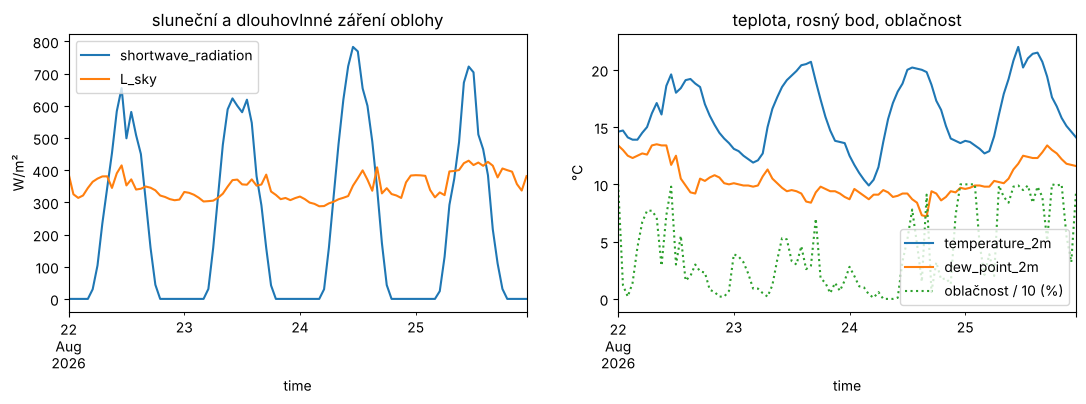

In [4]:
LAT, LON = 50.08, 14.42                     # ◀ parametr: místo pro počasí (Praha)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "UTC",
                "hourly": "shortwave_radiation,temperature_2m,dew_point_2m,wind_speed_10m,cloud_cover,surface_pressure"})
met = pd.DataFrame(w["hourly"]).assign(time=lambda d: pd.to_datetime(d.time)).set_index("time").dropna()
daily = met.shortwave_radiation.resample("D").sum() * 3600 / 1e6            # MJ/m² za den
best = daily.idxmax()
N_DAYS = 4                                   # ◀ parametr: kolik dní simulovat (nejslunečnější den je uprostřed)
start = best - pd.Timedelta(days=N_DAYS // 2)
F = met.loc[start: start + pd.Timedelta(days=N_DAYS) - pd.Timedelta(hours=1)].copy()
SIGMA = 5.670374e-8
F["Ta"] = F.temperature_2m + 273.15
F["e_a"] = 6.112 * np.exp(17.62 * F.dew_point_2m / (243.12 + F.dew_point_2m))          # hPa
eps_clear = 1.24 * (F.e_a / F.Ta) ** (1 / 7)                                          # Brutsaert 1975
F["L_sky"] = (eps_clear * (1 - F.cloud_cover / 100) + F.cloud_cover / 100) * SIGMA * F.Ta ** 4
F["q_a"] = 0.622 * F.e_a / F.surface_pressure
print(f"nejslunečnější den {best.date()} ({daily.max():.1f} MJ/m²), simulace {F.index[0]} až {F.index[-1]} UTC")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
F[["shortwave_radiation", "L_sky"]].plot(ax=ax[0]); ax[0].set(ylabel="W/m²", title="sluneční a dlouhovlnné záření oblohy")
F[["temperature_2m", "dew_point_2m"]].plot(ax=ax[1]); (F.cloud_cover / 10).plot(ax=ax[1], ls=":", label="oblačnost / 10 (%)")
ax[1].set(ylabel="°C", title="teplota, rosný bod, oblačnost"); ax[1].legend(); plt.show()

> **✏️ Úkol 1.** Najdi v grafech noc s jasnou a noc se zataženou oblohou. O kolik se v nich liší L↓ a proč? Co to znamená pro ochlazování povrchu v noci?

*Tvoje odpověď:* 

## 3. Model povrchu

Čistá radiace Rn = (1 − albedo) · S + ε · L↓ − ε · σ · Ts⁴ se dělí na citelné teplo H = h · (Ts − T_vzduch), výpar LE = β · (L_v/c_p) · h · (q_sat(Ts) − q_vzduch) a tok do země G = Rn − H − LE. Teplotu povrchu Ts posouvá G podle modelu force-restore (Noilhan a Planton 1989): dTs/dt = C_T · G − (2π/τ) · (Ts − T2), kde C_T = 2√(π/τ)/P a P je tepelná setrvačnost. β říká, kolik vody má povrch k dispozici (0 suchý beton, 1 mokrý povrch).

simulace 4 povrchů za 1 s


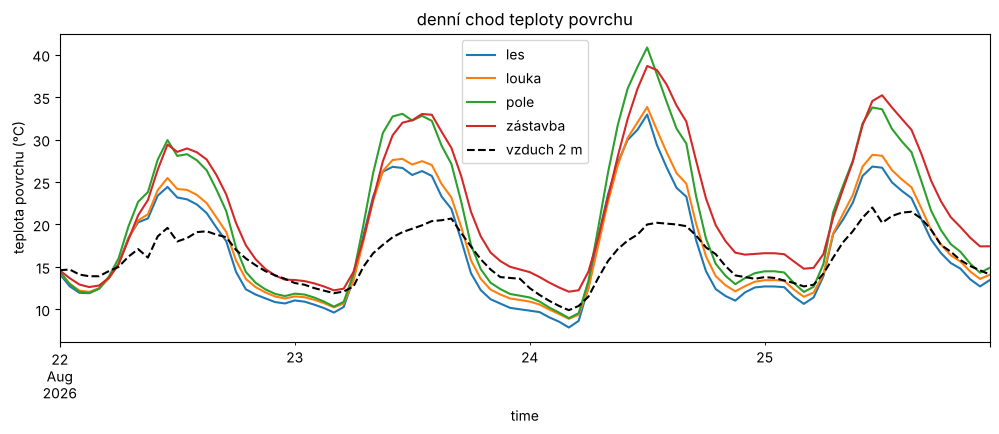

In [5]:
SURF = pd.DataFrame({                                             # ◀ parametr: vlastnosti povrchů (orientační)
    "albedo": albedo,
    "ε":      {"les": 0.99, "louka": 0.98, "pole": 0.97, "zástavba": 0.93},
    "β":      {"les": 0.7, "louka": 0.5, "pole": 0.2, "zástavba": 0.05},          # dostupnost vody pro výpar (0–1)
    "P":      {"les": 800, "louka": 1200, "pole": 1000, "zástavba": 2000},        # tepelná setrvačnost (J·m⁻²·K⁻¹·s⁻½)
})
WIND = 0.75                                  # ◀ parametr: vítr u povrchu jako podíl větru v 10 m
TAU, LV, CP = 86400.0, 2.45e6, 1005.0

def q_sat(T, p):
    e = 6.112 * np.exp(17.62 * (T - 273.15) / (243.12 + T - 273.15))
    return 0.622 * e / p

def simulate(albedo, eps, beta, P, F=F, dt=60):
    """Model force-restore (Noilhan a Planton 1989): teplota povrchu Ts a hlubší vrstvy T2 při skutečném počasí."""
    CT = 2 * np.sqrt(np.pi / TAU) / P
    Ts = T2 = F.Ta.iloc[0]
    out = []
    for t, r in F.iterrows():
        h = 5.7 + 3.8 * r.wind_speed_10m * WIND
        for _ in range(int(3600 / dt)):
            Rn = (1 - albedo) * r.shortwave_radiation + eps * r.L_sky - eps * SIGMA * Ts ** 4
            H = h * (Ts - r.Ta)
            LE = beta * LV / CP * h * (q_sat(Ts, r.surface_pressure) - r.q_a)
            G = Rn - H - LE
            Ts, T2 = Ts + dt * (CT * G - 2 * np.pi / TAU * (Ts - T2)), T2 + dt * (Ts - T2) / TAU
        out.append({"time": t, "Ts": Ts - 273.15, "Rn": Rn, "H": H, "LE": LE, "G": G})
    return pd.DataFrame(out).set_index("time")

t0 = time.time()
runs = {name: simulate(s.albedo, s["ε"], s["β"], s.P) for name, s in SURF.iterrows()}
print(f"simulace {len(runs)} povrchů za {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(12, 4))
for name, r in runs.items():
    r.Ts.plot(ax=ax, label=name)
F.temperature_2m.plot(ax=ax, color="k", ls="--", label="vzduch 2 m")
ax.set(ylabel="teplota povrchu (°C)", title="denní chod teploty povrchu"); ax.legend(); plt.show()

> **✏️ Úkol 2.** Který povrch je nejteplejší v poledne a který v noci? Proč je zástavba v poledne chladnější než pole, i když skoro nic neodpařuje, a v noci naopak nejteplejší? V kolik hodin UTC má povrch maximum a proč až po slunečním poledni (v Praze kolem 11:00 UTC)?

*Tvoje odpověď:* 

## 4. Kam se energie během dne rozdělí

In [6]:
day = F.index.normalize() == best
rows = {}
for name, r in runs.items():
    d = r[day]
    rows[name] = {"Rn (MJ/m²)": d.Rn.sum() * 3600 / 1e6, "H (MJ/m²)": d.H.sum() * 3600 / 1e6, "LE (MJ/m²)": d.LE.sum() * 3600 / 1e6,
                  "G (MJ/m²)": d.G.sum() * 3600 / 1e6, "Bowenův poměr H/LE": d.H.sum() / d.LE.sum(),
                  "max Ts (°C)": d.Ts.max(), "hodina max (UTC)": d.Ts.idxmax().hour, "min Ts noc (°C)": d.Ts.min()}
pd.DataFrame(rows).T.round(2)

,Rn (MJ/m²),H (MJ/m²),LE (MJ/m²),G (MJ/m²),Bowenův poměr H/LE,max Ts (°C),hodina max (UTC),min Ts noc (°C)
les,12.30,1.58,10.13,0.59,0.16,32.96,12.0,7.86
louka,11.57,2.45,8.17,0.96,0.30,33.85,12.0,8.88
pole,10.87,4.80,4.92,1.15,0.97,40.86,12.0,8.97
zástavba,10.30,6.46,1.36,2.48,4.74,38.68,12.0,12.08


> **✏️ Úkol 3.** Kolik procent čisté radiace spotřebuje les na výpar a kolik zástavba? Co říká Bowenův poměr a proč u lesa vychází pod 1? Proč je denní součet G kladný, tj. co se během slunečných dní děje s teplem v zemi?

*Tvoje odpověď:* 

## 5. Setrvačnost a voda

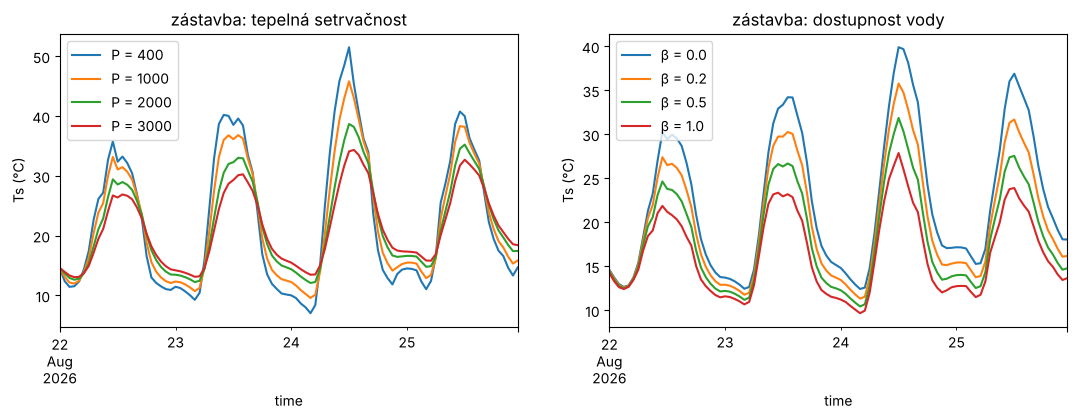

In [7]:
TEST = "zástavba"                            # ◀ parametr: povrch, na kterém zkoušíme vlastnosti
s = SURF.loc[TEST]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for P in [400, 1000, 2000, 3000]:
    simulate(s.albedo, s["ε"], s["β"], P).Ts.plot(ax=ax[0], label=f"P = {P}")
for beta in [0.0, 0.2, 0.5, 1.0]:
    simulate(s.albedo, s["ε"], beta, s.P).Ts.plot(ax=ax[1], label=f"β = {beta}")
ax[0].set(ylabel="Ts (°C)", title=f"{TEST}: tepelná setrvačnost"); ax[0].legend()
ax[1].set(ylabel="Ts (°C)", title=f"{TEST}: dostupnost vody"); ax[1].legend(); plt.show()

> **✏️ Úkol 4.** Jak se s rostoucí tepelnou setrvačností P mění denní rozkmit teploty a čas maxima? A jak s dostupností vody β? Který z obou zásahů by víc pomohl proti přehřívání ulic ve dne a který v noci (zeleň a zalévání, nebo jiné materiály)?

*Tvoje odpověď:* 

## 6. Srovnání s rovnováhou ze základní verze

In [8]:
from scipy.optimize import brentq
noon = runs["zástavba"][day].Ts.idxmax()
r = F.loc[noon]
h = 5.7 + 3.8 * r.wind_speed_10m * WIND
cmp = {}
for name, s in SURF.iterrows():
    f = lambda T: (1 - s.albedo) * r.shortwave_radiation + s["ε"] * r.L_sky - s["ε"] * SIGMA * T ** 4 - h * (T - r.Ta)
    cmp[name] = {"rovnováha bez výparu a země (°C)": brentq(f, 200, 400) - 273.15, "model force-restore (°C)": runs[name].Ts[noon]}
print(f"hodina {noon} UTC, S = {r.shortwave_radiation:.0f} W/m², vzduch {r.temperature_2m:.1f} °C")
pd.DataFrame(cmp).T.round(1)

hodina 2026-08-24 12:00:00 UTC, S = 769 W/m², vzduch 20.0 °C


,rovnováha bez výparu a země (°C),model force-restore (°C)
les,60.0,33.0
louka,59.4,33.8
pole,61.0,40.9
zástavba,61.2,38.7


> **✏️ Úkol 5.** O kolik stupňů je rovnovážná teplota bez výparu a toku do země vyšší než teplota z modelu? Které dva členy bilance rozdíl vysvětlují a u kterého povrchu je který důležitější? Proč termokamera z dronu v poledne ukáže mezi lesem a polem rozdíl, ze kterého lze usuzovat na vodní stres?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Změň `LAT, LON` na jiné místo (třeba horskou stanici) nebo `N_DAYS` na 10 a podívej se, jak se mění noční minima při jasné a zatažené obloze. Proč jsou mrazové kotliny nejchladnější za jasných a klidných nocí?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); registr AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje.
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Počasí: Open-Meteo.com (CC BY 4.0). https://open-meteo.com
- Liang, S. (2001). Narrowband to broadband conversions of land surface albedo I: Algorithms. *Remote Sensing of Environment* 76, 213–238. https://doi.org/10.1016/S0034-4257(00)00205-4
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744. https://doi.org/10.1029/WR011i005p00742
- Crawford, T. M., Duchon, C. E. (1999). An improved parameterization for estimating effective atmospheric emissivity for use in calculating daytime downwelling longwave radiation. *Journal of Applied Meteorology* 38, 474–480.
- Noilhan, J., Planton, S. (1989). A simple parameterization of land surface processes for meteorological models. *Monthly Weather Review* 117, 536–549. https://doi.org/10.1175/1520-0493(1989)117<0536:ASPOLS>2.0.CO;2
- Oke, T. R., Mills, G., Christen, A., Voogt, J. A. (2017). *Urban Climates*. Cambridge University Press.

### Jak citovat

OpenSkyLab (2026). Kam zmizí sluneční záření, pokročilá verze: denní chod teploty povrchu [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/radiation_balance_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*